# Ejercicio 3: convolución, ReLU y max pooling sobre una imagen RGB

**Juan David Sierra Orozco**
Inteligencia Artificial (SI3003), EAFIT, clase de redes convolucionales

## Enunciado

Tomar una imagen en RGB. Aplicar convolución con 3 kernels diferentes de 3x3 y, en cada salida de la convolución, aplicar ReLU. Luego hacer max pooling de 2x2. Mostrar los mapas de características resultantes después de estas 3 etapas.

## Cómo se lee el enunciado

Las **3 etapas** son **convolución, ReLU y max pooling**, el bloque `Conv → ReLU → Pool` del flujo de una CNN. Los **3 kernels** son 3 filtros que se aplican a la misma imagen, así que el resultado son **3 mapas de características**, uno por filtro. Es exactamente lo que hace una capa convolucional con $C_{out}=3$.

El enunciado admite otra lectura, las tres convoluciones encadenadas una tras otra. Se resuelve al final, en la sección 7, como variante.

## Las tres operaciones, con la notación de la clase

**Convolución multicanal.** Para una imagen RGB ($C_{in}=3$), cada filtro tiene profundidad 3 y **suma sobre los canales**, así que produce **un** mapa:

$$C(i,j) = \sum_{d=0}^{2}\sum_{m=0}^{2}\sum_{n=0}^{2} I_d(i+m,\,j+n)\cdot K_d(m,n) + b$$

**ReLU:** $\;\text{ReLU}(x)=\max(0,x)$

**Max pooling** con ventana 2x2 y paso 2: cada bloque de 2x2 se reemplaza por su máximo. El tamaño de salida es $O=\lfloor (W-K)/S\rfloor+1$.

## Una decisión de diseño

El enunciado da kernels de 3x3. En una CNN real cada filtro es de 3x3x3, con pesos **independientes** por canal (27 números que se aprenden). Aquí cada filtro de 3x3 se **repite en los tres canales** (9 números), que es lo más fiel al enunciado. Como el filtro es el mismo en R, G y B, la suma sobre canales equivale a filtrar la suma $R+G+B$: el color se pierde y quedan las estructuras de brillo.

In [1]:
import os
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from scipy.signal import correlate2d

plt.rcParams["figure.dpi"] = 80     # figuras mas livianas dentro del archivo


def cargar_imagen_rgb(ruta=None):
    """Foto de ejemplo incluida con matplotlib si no se da ruta. Valores en [0, 255]."""
    if ruta is None:
        ruta = os.path.join(matplotlib.get_data_path(), "sample_data", "grace_hopper.jpg")
    return np.asarray(Image.open(ruta).convert("RGB"), dtype=float)


def convolucion2d(img, kernel):
    """C(i,j) = suma_m suma_n I(i+m, j+n) K(m,n), con relleno de ceros (misma dimension)."""
    k = kernel.shape[0]
    img = np.pad(img, k // 2, mode="constant")
    alto, ancho = img.shape[0] - k + 1, img.shape[1] - k + 1
    salida = np.zeros((alto, ancho))
    for m in range(k):
        for n in range(k):
            salida += kernel[m, n] * img[m:m + alto, n:n + ancho]
    return salida


def conv_multicanal(img, kernel, sesgo=0.0):
    """Filtro de 3x3xC: se convoluciona cada canal y se SUMA sobre los canales.
    Devuelve un solo mapa, como en la formula de la clase."""
    return sum(convolucion2d(img[..., d], kernel[..., d]) for d in range(img.shape[2])) + sesgo


def relu(x):
    return np.maximum(x, 0)


def max_pooling(x, k=2):
    """Maximo de cada bloque k x k sin traslape (paso = k)."""
    alto, ancho = (x.shape[0] // k) * k, (x.shape[1] // k) * k
    bloques = x[:alto, :ancho].reshape(alto // k, k, ancho // k, k)
    return bloques.max(axis=(1, 3))

---

## 1. La imagen y los tres kernels

Se eligen tres kernels de bordes, cada uno sensible a una orientación distinta: vertical, horizontal y diagonal. Es lo que hacen los filtros de la primera capa de una CNN, y permite ver con claridad qué detecta cada mapa.

In [2]:
imagen = cargar_imagen_rgb()
print("Imagen RGB:", imagen.shape, " (alto, ancho, canales)")

kernels = {
    "vertical":   np.array([[-1,  0,  1],
                            [-2,  0,  2],
                            [-1,  0,  1]], dtype=float),
    "horizontal": np.array([[-1, -2, -1],
                            [ 0,  0,  0],
                            [ 1,  2,  1]], dtype=float),
    "diagonal":   np.array([[ 0,  1,  2],
                            [-1,  0,  1],
                            [-2, -1,  0]], dtype=float),
}

# Cada filtro de 3x3 se repite en los 3 canales para formar el volumen de 3x3x3.
filtros = {nombre: np.stack([K, K, K], axis=-1) for nombre, K in kernels.items()}
SESGO = 0.0

for nombre, K in kernels.items():
    print(f"\nKernel {nombre} (suma = {K.sum():.0f}):\n{K}")
print("\nForma de cada filtro completo:", filtros["vertical"].shape, " (alto, ancho, canales)")

Imagen RGB: (600, 512, 3)  (alto, ancho, canales)

Kernel vertical (suma = 0):
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]

Kernel horizontal (suma = 0):
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Kernel diagonal (suma = 0):
[[ 0.  1.  2.]
 [-1.  0.  1.]
 [-2. -1.  0.]]

Forma de cada filtro completo: (3, 3, 3)  (alto, ancho, canales)


---

## 2. Comprobar que las funciones están bien

- La convolución multicanal contra SciPy (suma de las correlaciones por canal).
- El max pooling contra una versión con ciclos.
- El tamaño de salida contra la fórmula de la clase, $O=\lfloor (W-K)/S\rfloor+1$.

In [3]:
K = kernels["vertical"]

# 1) Convolucion multicanal contra SciPy.
propio = conv_multicanal(imagen, filtros["vertical"], SESGO)
referencia = sum(correlate2d(imagen[..., d], K, mode="same") for d in range(3))
print("conv multicanal == SciPy       :", np.allclose(propio, referencia))

# 2) Max pooling contra una version con ciclos, en un mapa de prueba.
mapa = relu(propio)
ingenuo = np.array([[mapa[2*i:2*i+2, 2*j:2*j+2].max() for j in range(mapa.shape[1] // 2)]
                    for i in range(mapa.shape[0] // 2)])
print("max pooling == version ingenua :", np.array_equal(max_pooling(mapa), ingenuo))

# 3) Tamano de salida.
esperado = ((mapa.shape[0] - 2) // 2 + 1, (mapa.shape[1] - 2) // 2 + 1)
print(f"tamano tras pooling: {max_pooling(mapa).shape}   formula de la clase: {esperado}")

# 4) Un ejemplo pequeno, a mano, para ver que hace ReLU y el pooling.
x = np.array([[ 1., -3.,  2.,  1.],
              [ 4.,  6., -5.,  2.],
              [-7.,  2.,  1.,  0.],
              [ 3., -8.,  4.,  9.]])
print("\nEjemplo pequeno:\nentrada:\n", x, "\ntras ReLU:\n", relu(x), "\ntras max pooling 2x2:\n", max_pooling(relu(x)))

conv multicanal == SciPy       : True
max pooling == version ingenua : True
tamano tras pooling: (300, 256)   formula de la clase: (300, 256)

Ejemplo pequeno:
entrada:
 [[ 1. -3.  2.  1.]
 [ 4.  6. -5.  2.]
 [-7.  2.  1.  0.]
 [ 3. -8.  4.  9.]] 
tras ReLU:
 [[1. 0. 2. 1.]
 [4. 6. 0. 2.]
 [0. 2. 1. 0.]
 [3. 0. 4. 9.]] 
tras max pooling 2x2:
 [[6. 2.]
 [3. 9.]]


---

## 3. Las tres etapas, para cada filtro

Cada filtro pasa por **convolución, ReLU y max pooling 2x2**. Se guarda la salida de cada etapa para poder mostrarlas.

In [4]:
etapas = {}
for nombre in filtros:
    tras_conv = conv_multicanal(imagen, filtros[nombre], SESGO)     # etapa 1: convolucion
    tras_relu = relu(tras_conv)                                     # etapa 2: ReLU
    tras_pool = max_pooling(tras_relu, k=2)                         # etapa 3: max pooling 2x2
    etapas[nombre] = {"conv": tras_conv, "relu": tras_relu, "pool": tras_pool}

print(f"{'filtro':<11} | {'tras conv':>12} | {'tras ReLU':>12} | {'tras pool':>12} | {'ceros tras ReLU':>15} | {'valores':>17}")
print("-" * 92)
for nombre, e in etapas.items():
    ceros = 100 * np.mean(e["relu"] == 0)
    print(f"{nombre:<11} | {str(e['conv'].shape):>12} | {str(e['relu'].shape):>12} | {str(e['pool'].shape):>12} | "
          f"{ceros:>14.0f}% | {e['relu'].size:>7} -> {e['pool'].size:<6}")

volumen = np.stack([etapas[n]["pool"] for n in etapas], axis=-1)
print(f"\nVolumen de salida (3 mapas apilados): {volumen.shape}   (alto, ancho, mapas)")

filtro      |    tras conv |    tras ReLU |    tras pool | ceros tras ReLU |           valores
--------------------------------------------------------------------------------------------
vertical    |   (600, 512) |   (600, 512) |   (300, 256) |             51% |  307200 -> 76800 
horizontal  |   (600, 512) |   (600, 512) |   (300, 256) |             51% |  307200 -> 76800 
diagonal    |   (600, 512) |   (600, 512) |   (300, 256) |             51% |  307200 -> 76800 

Volumen de salida (3 mapas apilados): (300, 256, 3)   (alto, ancho, mapas)


Dos cosas que ya se leen en la tabla. **ReLU deja en cero cerca de la mitad de los valores**: un filtro simétrico da respuestas positivas y negativas en proporciones parecidas, y solo sobreviven las positivas. **El pooling reduce cuatro veces la cantidad de valores** (de 307200 a 76800 por mapa) y el mapa pasa de 600x512 a 300x256.

---

## 4. Ver cada etapa

Una fila por filtro y una columna por etapa: el kernel, la salida de la convolución, después de ReLU y después del max pooling.

- La **convolución** se dibuja con una escala divergente centrada en cero: **rojo** para respuestas positivas y **azul** para negativas.
- **ReLU** elimina todo el azul.
- El **max pooling** encoge el mapa a la mitad en cada dimensión conservando los máximos.

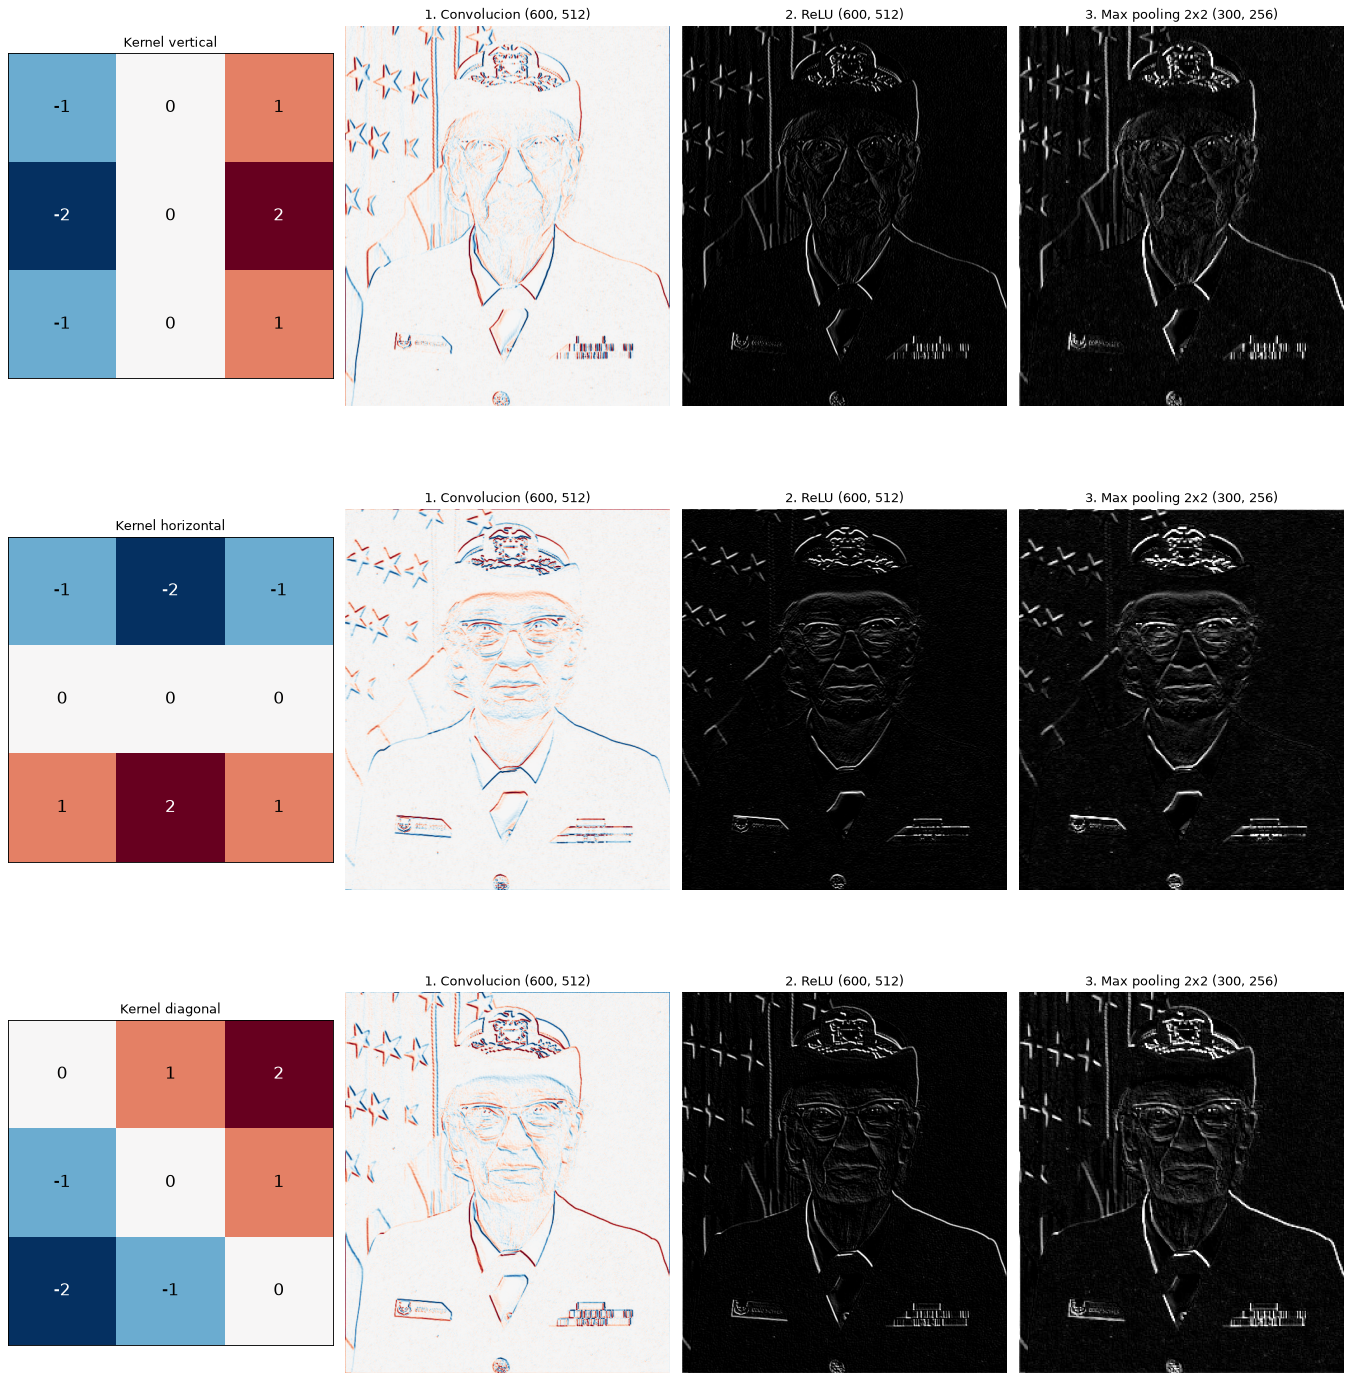

In [5]:
def escala(mapa):
    """Tope de la escala: el percentil 99.5, para que unos pocos valores extremos no aplasten el contraste."""
    return np.percentile(np.abs(mapa), 99.5)


fig, ejes = plt.subplots(3, 4, figsize=(17, 19))

for fila, (nombre, e) in enumerate(etapas.items()):
    tope = escala(e["conv"])

    # kernel, con sus valores escritos
    K = kernels[nombre]
    ejes[fila, 0].imshow(K, cmap="RdBu_r", vmin=-2, vmax=2)
    for i in range(3):
        for j in range(3):
            ejes[fila, 0].text(j, i, f"{K[i, j]:.0f}", ha="center", va="center", fontsize=15,
                                color="white" if abs(K[i, j]) >= 2 else "black")
    ejes[fila, 0].set_title(f"Kernel {nombre}")
    ejes[fila, 0].set_xticks([]); ejes[fila, 0].set_yticks([])

    ejes[fila, 1].imshow(e["conv"], cmap="RdBu_r", vmin=-tope, vmax=tope)
    ejes[fila, 1].set_title(f"1. Convolucion {e['conv'].shape}")

    ejes[fila, 2].imshow(e["relu"], cmap="gray", vmin=0, vmax=tope)
    ejes[fila, 2].set_title(f"2. ReLU {e['relu'].shape}")

    ejes[fila, 3].imshow(e["pool"], cmap="gray", vmin=0, vmax=tope)
    ejes[fila, 3].set_title(f"3. Max pooling 2x2 {e['pool'].shape}")

    for eje in ejes[fila, 1:]:
        eje.axis("off")

plt.tight_layout()
plt.show()

---

## 5. Los mapas de características resultantes

Este es el resultado que pide el enunciado: los **3 mapas de características** después de las tres etapas, de tamaño 300x256. El cuarto panel apila los tres mapas como los canales rojo, verde y azul de una imagen, para ver los tres filtros a la vez: el color indica qué orientación dominó en cada zona.

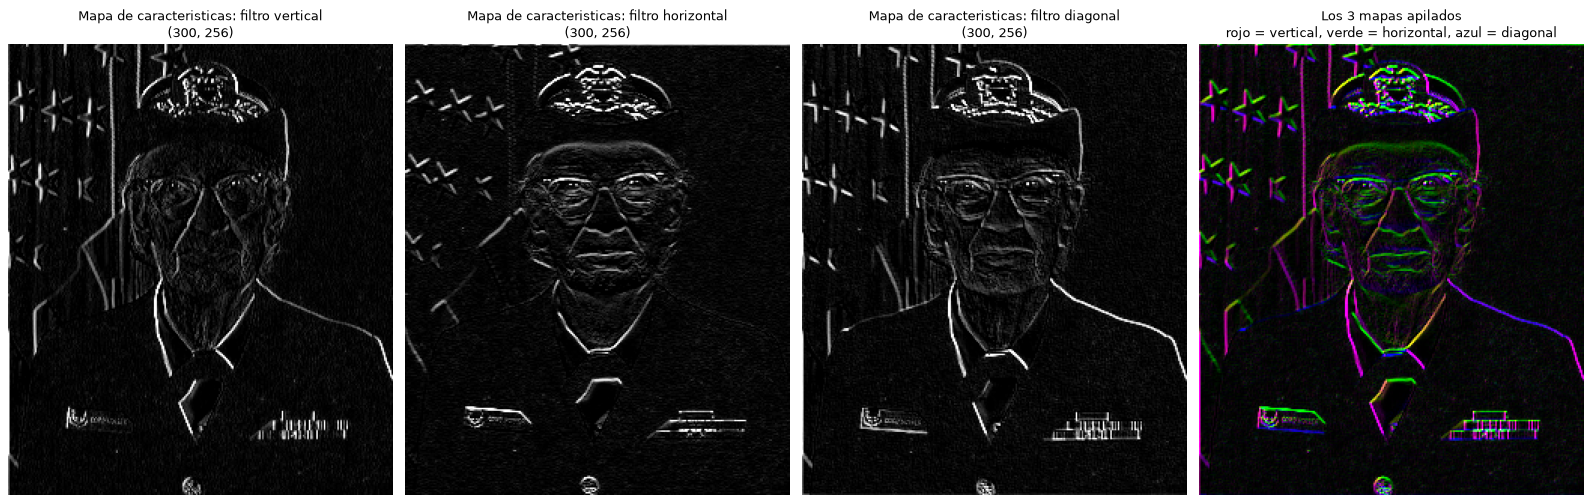

In [6]:
fig, ejes = plt.subplots(1, 4, figsize=(20, 6.5))

for eje, (nombre, e) in zip(ejes[:3], etapas.items()):
    eje.imshow(e["pool"], cmap="gray", vmin=0, vmax=escala(e["conv"]))
    eje.set_title(f"Mapa de caracteristicas: filtro {nombre}\n{e['pool'].shape}")
    eje.axis("off")

# Los tres mapas como canales R, G, B (cada uno normalizado por separado).
compuesto = np.stack([np.clip(etapas[n]["pool"] / escala(etapas[n]["conv"]), 0, 1) for n in etapas], axis=-1)
ejes[3].imshow(compuesto)
ejes[3].set_title("Los 3 mapas apilados\nrojo = vertical, verde = horizontal, azul = diagonal")
ejes[3].axis("off")

plt.tight_layout()
plt.show()

Cada mapa responde a una orientación distinta. El filtro **vertical** se enciende en las franjas de la bandera y en el costado de la cara, el **horizontal** en los travesaños de las estrellas, el borde del sombrero y el cuello del uniforme, y el **diagonal** en las líneas inclinadas. En el mapa apilado, las zonas blancas son donde varias orientaciones responden a la vez, y el color puro donde domina una sola.

### 5.1 Qué conservó y qué descartó el pooling

In [7]:
for nombre, e in etapas.items():
    print(f"{nombre:<11} maximo antes del pooling = {e['relu'].max():8.1f}   despues = {e['pool'].max():8.1f}"
          f"   | promedio antes = {e['relu'].mean():6.2f}   despues = {e['pool'].mean():6.2f}")

vertical    maximo antes del pooling =   2964.0   despues =   2964.0   | promedio antes =  64.62   despues = 116.71
horizontal  maximo antes del pooling =   2940.0   despues =   2940.0   | promedio antes =  56.95   despues = 105.69
diagonal    maximo antes del pooling =   2888.0   despues =   2888.0   | promedio antes =  66.22   despues = 121.30


El **máximo global no cambia**: el pooling nunca pierde la respuesta más fuerte. En cambio el **promedio sube**, porque de cada bloque de 4 valores se conserva el mayor y se descartan los otros tres, que son casi siempre los ceros que dejó el ReLU. Se quedó con lo más informativo y tiró lo demás.

### 5.2 El vector aplanado (Flatten)

Es el último paso antes de las capas totalmente conectadas: los 3 mapas de 300x256 se convierten en **un único vector** de $300\times256\times3=230400$ valores.

Se aplana con la convención de Keras (canales al final), así que los tres mapas quedan **intercalados**: las posiciones 0, 3, 6, ... son del filtro vertical, las 1, 4, 7, ... del horizontal y las 2, 5, 8, ... del diagonal.

In [8]:
vector = volumen.flatten()      # orden C sobre (alto, ancho, mapas)

print("Volumen:", volumen.shape, " -> vector:", vector.shape, "  (300 x 256 x 3 =", 300 * 256 * 3, ")")
print("Se reconstruye el volumen               :", np.array_equal(vector.reshape(volumen.shape), volumen))
print("vector[c::3] es el mapa c (intercalados) :",
      all(np.array_equal(vector[c::3].reshape(300, 256), volumen[..., c]) for c in range(3)))
print(f"minimo = {vector.min():.1f}   maximo = {vector.max():.1f}   media = {vector.mean():.2f}   ceros = {100 * np.mean(vector == 0):.1f}%")
print("\nPrimeros 15 valores:", vector[:15].tolist())

Volumen: (300, 256, 3)  -> vector: (230400,)   (300 x 256 x 3 = 230400 )
Se reconstruye el volumen               : True
vector[c::3] es el mapa c (intercalados) : True
minimo = 0.0   maximo = 2964.0   media = 114.56   ceros = 21.7%

Primeros 15 valores: [535.0, 551.0, 420.0, 70.0, 617.0, 150.0, 11.0, 655.0, 75.0, 0.0, 628.0, 45.0, 125.0, 640.0, 75.0]


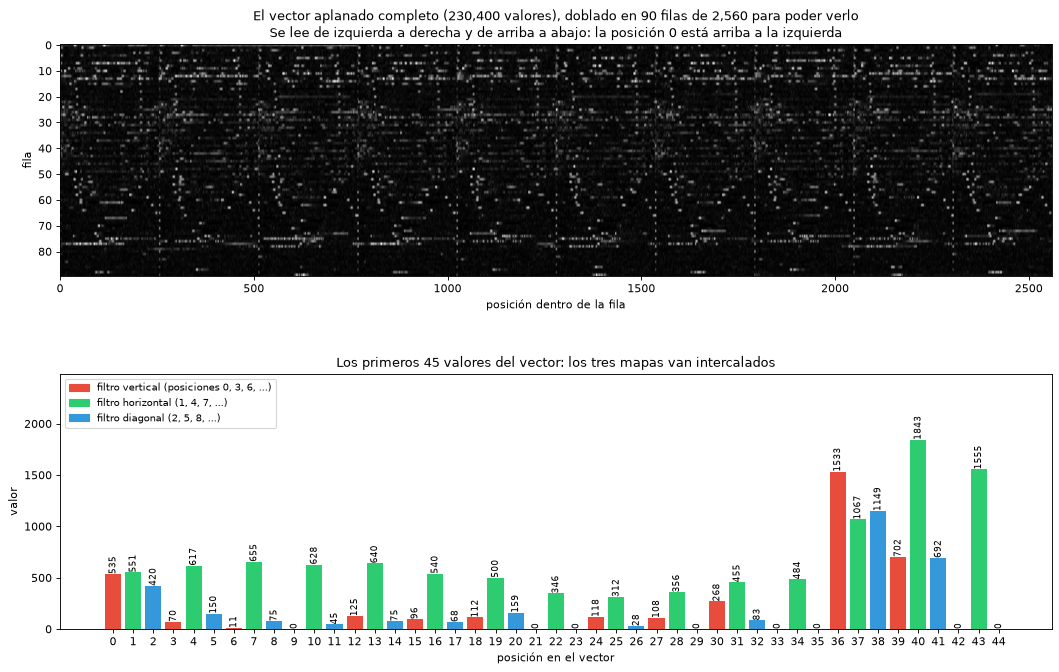

In [9]:
from matplotlib.patches import Patch

fig = plt.figure(figsize=(16, 9.5))
cuadricula = fig.add_gridspec(2, 1, height_ratios=[1, 1.1], hspace=0.4)

# Arriba: el vector completo, doblado en filas para poder verlo.
FILAS = 90
tira = vector.reshape(FILAS, -1)
eje_1 = fig.add_subplot(cuadricula[0])
eje_1.imshow(tira, cmap="gray", aspect="auto", vmin=0, vmax=np.percentile(vector, 99))
eje_1.set_title(f"El vector aplanado completo ({vector.size:,} valores), doblado en {FILAS} filas de {tira.shape[1]:,} para poder verlo\n"
                "Se lee de izquierda a derecha y de arriba a abajo: la posición 0 está arriba a la izquierda")
eje_1.set_xlabel("posición dentro de la fila")
eje_1.set_ylabel("fila")

# Abajo: los primeros valores, con su numero.
N = 45
colores = ["#e74c3c", "#2ecc71", "#3498db"]
eje_2 = fig.add_subplot(cuadricula[1])
eje_2.bar(range(N), vector[:N], color=[colores[i % 3] for i in range(N)])
for i in range(N):
    eje_2.text(i, vector[i], f"{vector[i]:.0f}", ha="center", va="bottom", fontsize=8, rotation=90)
eje_2.set_xticks(range(N))
eje_2.set_xlabel("posición en el vector")
eje_2.set_ylabel("valor")
eje_2.set_ylim(0, vector[:N].max() * 1.35)
eje_2.set_title(f"Los primeros {N} valores del vector: los tres mapas van intercalados")
eje_2.legend(handles=[Patch(color=colores[0], label="filtro vertical (posiciones 0, 3, 6, ...)"),
                      Patch(color=colores[1], label="filtro horizontal (1, 4, 7, ...)"),
                      Patch(color=colores[2], label="filtro diagonal (2, 5, 8, ...)")],
             loc="upper left", fontsize=9)
plt.show()

En la tira de arriba se distingue el contenido de la imagen: las zonas oscuras son fondo sin bordes (ceros tras ReLU y pooling) y las claras son donde algún filtro respondió con fuerza. Abajo se ve el intercalado: cada tres valores consecutivos son la respuesta de los tres filtros en un mismo píxel del mapa.

---

## 6. La imagen original, para comparar

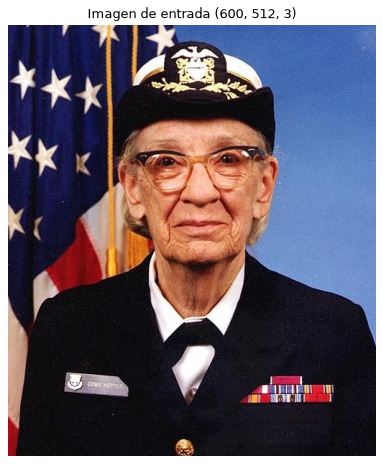

In [10]:
plt.figure(figsize=(6, 7))
plt.imshow(imagen.astype(np.uint8))
plt.title(f"Imagen de entrada {imagen.shape}")
plt.axis("off")
plt.show()

---

## 7. Variante: las tres convoluciones en cascada

Si el enunciado se lee como tres convoluciones **encadenadas**, la salida de cada una alimenta a la siguiente, con ReLU entre ellas y un único max pooling al final:

$$I \xrightarrow{K_1} \text{ReLU} \xrightarrow{K_2} \text{ReLU} \xrightarrow{K_3} \text{ReLU} \xrightarrow{\text{pool}\ 2\times2} \text{mapa final}$$

La primera convolución recibe la imagen RGB (filtro de 3x3x3) y ya produce **un solo canal**, así que las otras dos son filtros de 3x3 sobre un mapa de un canal. Se usan los mismos tres kernels de la sección 1.

etapa 1 (kernel vertical  ): (600, 512)   ceros tras ReLU: 51%
etapa 2 (kernel horizontal): (600, 512)   ceros tras ReLU: 54%
etapa 3 (kernel diagonal  ): (600, 512)   ceros tras ReLU: 56%
tras max pooling             : (300, 256)


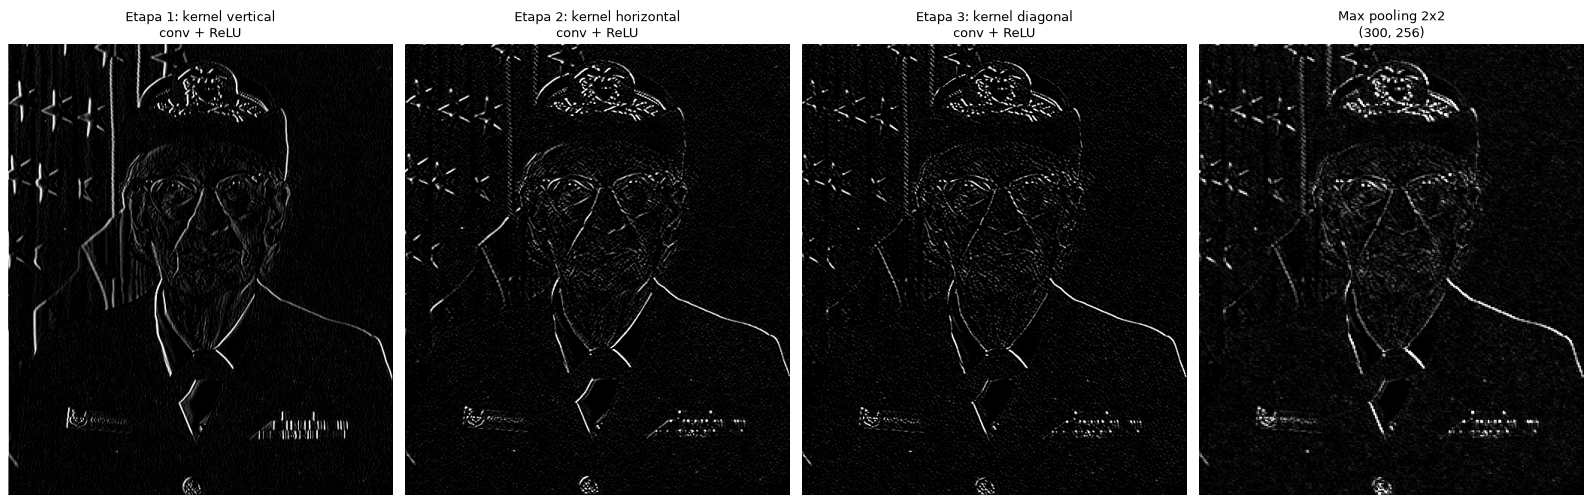

In [11]:
nombres = list(kernels)

mapa_1 = relu(conv_multicanal(imagen, filtros[nombres[0]], SESGO))       # conv 1 + ReLU
mapa_2 = relu(convolucion2d(mapa_1, kernels[nombres[1]]))                # conv 2 + ReLU
mapa_3 = relu(convolucion2d(mapa_2, kernels[nombres[2]]))                # conv 3 + ReLU
mapa_final = max_pooling(mapa_3, k=2)                                    # max pooling 2x2

for i, (m, n) in enumerate([(mapa_1, nombres[0]), (mapa_2, nombres[1]), (mapa_3, nombres[2])], start=1):
    print(f"etapa {i} (kernel {n:<10}): {m.shape}   ceros tras ReLU: {100*np.mean(m == 0):.0f}%")
print(f"tras max pooling             : {mapa_final.shape}")

fig, ejes = plt.subplots(1, 4, figsize=(20, 6.5))
paneles = [(mapa_1, f"Etapa 1: kernel {nombres[0]}\nconv + ReLU"),
           (mapa_2, f"Etapa 2: kernel {nombres[1]}\nconv + ReLU"),
           (mapa_3, f"Etapa 3: kernel {nombres[2]}\nconv + ReLU"),
           (mapa_final, f"Max pooling 2x2\n{mapa_final.shape}")]
for eje, (m, titulo) in zip(ejes, paneles):
    eje.imshow(m, cmap="gray", vmin=0, vmax=np.percentile(m, 99.5))
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()

En la cascada cada etapa deja el mapa **más disperso y más abstracto**: sobreviven cada vez menos activaciones, y ya no corresponden a bordes de la imagen sino a bordes de bordes, es decir, a patrones de nivel más alto. Es la razón por la que las CNN profundas apilan varias capas: las primeras detectan trazos simples y las siguientes los combinan en formas.

---

## 8. Conclusiones

**Un filtro es un detector de un patrón, y una capa convolucional es un conjunto de detectores.** Tres filtros dieron tres mapas, cada uno encendido donde aparecía su orientación. Con $C_{out}$ filtros la salida es un volumen de $C_{out}$ mapas apilados, no una imagen.

**ReLU aporta la no linealidad y la dispersión.** Deja en cero cerca de la mitad de las activaciones y conserva solo las respuestas positivas. En la variante en cascada esa dispersión aumenta con cada etapa.

**El pooling comprime sin perder lo esencial.** Redujo cuatro veces los valores de cada mapa, y el máximo global de cada mapa no cambió. Además da cierta tolerancia a pequeños desplazamientos, porque el máximo de una ventana casi no cambia si el borde se mueve un píxel dentro de ella.

**Todo se comprobó contra una referencia.** La convolución multicanal coincide con SciPy, el max pooling con una versión con ciclos, y los tamaños con la fórmula de la clase. Lo que aquí se fija a mano, los kernels, es justamente lo que una CNN aprende con backpropagation.